# Multimodal AI: Learning Guide

## Overview
This notebook covers multimodal AI systems that process and understand multiple types of data (text, images, audio, etc.) simultaneously.

## Part 1: What is Multimodal AI?

Multimodal AI systems can:
- Understand relationships between different data types
- Generate content across modalities
- Process queries involving multiple inputs

Common applications:
- Image captioning
- Visual Question Answering (VQA)
- Cross-modal search
- Video description
- Speech-to-text (STT)
- Text-to-speech (TTS)
- Text-to-image generation

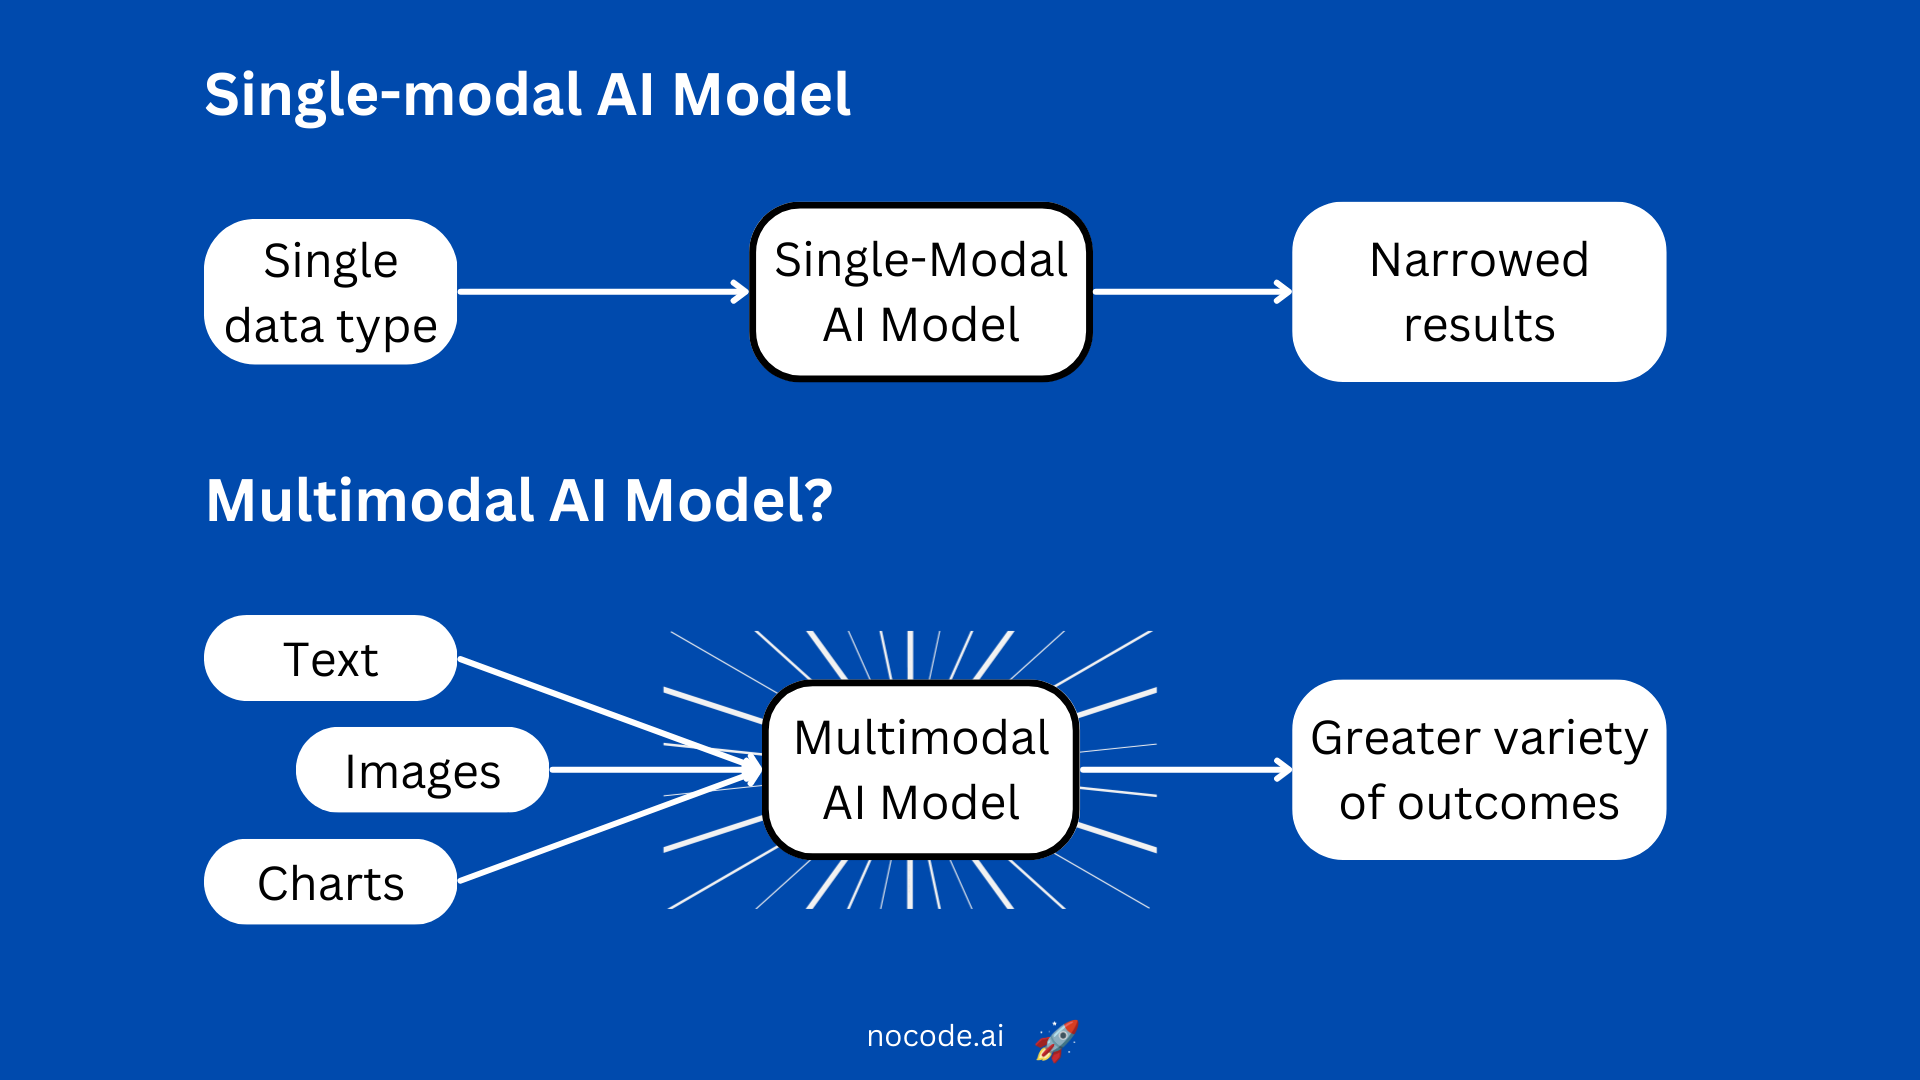

## Part 2: Setup and Dependencies

Install required packages:

In [ ]:
# Uncomment and run if packages need to be installed
!pip install transformers torch torchvision pillow matplotlib requests
!pip install open-clip-torch timm librosa soundfile pydub sentencepiece

In [ ]:
import torch
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import librosa
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms

from transformers import (
    BlipProcessor, BlipForConditionalGeneration,
    ViltProcessor, ViltForQuestionAnswering,
    Wav2Vec2Processor, Wav2Vec2ForCTC,
    SpeechT5Processor, SpeechT5ForTextToSpeech,
    SpeechT5HifiGan
)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

/home/sazzad/miniconda3/envs/ostad/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.11.0+cu130
CUDA available: False


/home/sazzad/miniconda3/envs/ostad/lib/python3.11/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12080). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


## Part 3: Image Captioning

Image captioning generates natural language descriptions of images.

In [ ]:
print("Loading BLIP model for image captioning...")
captioning_processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
captioning_model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base")
print("Model loaded successfully!")

Loading BLIP model for image captioning...


Loading weights: 100%|██████████| 473/473 [00:00<00:00, 50686.13it/s]
BlipForConditionalGeneration LOAD REPORT from: Salesforce/blip-image-captioning-base
Key                                       | Status     |  | 
------------------------------------------+------------+--+-
text_decoder.bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded successfully!


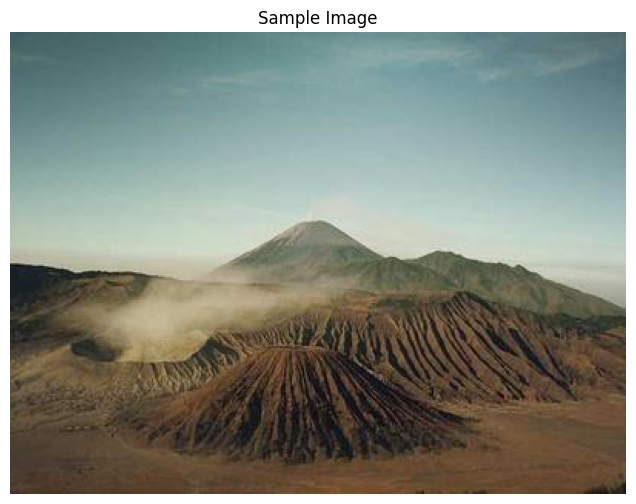

Generated Caption: an aerial view of a volcano in indonesia


In [ ]:
def load_image(image_url):
    response = requests.get(image_url)
    return Image.open(BytesIO(response.content))

def generate_caption(image, processor, model):
    inputs = processor(images=image, return_tensors="pt")
    outputs = model.generate(**inputs, max_length=50, num_beams=5)
    caption = processor.decode(outputs[0], skip_special_tokens=True)
    return caption

sample_image_url = "https://picsum.photos/seed/123/400/300"
image = load_image(sample_image_url)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis('off')
plt.title("Sample Image")
plt.show()

caption = generate_caption(image, captioning_processor, captioning_model)
print(f"Generated Caption: {caption}")

## Part 4: Visual Question Answering (VQA)

VQA models answer questions about images.

In [ ]:
print("Loading VILT model for Visual QA...")
vqa_processor = ViltProcessor.from_pretrained("dandelin/vilt-b32-finetuned-vqa")
vqa_model = ViltForQuestionAnswering.from_pretrained("dandelin/vilt-b32-finetuned-vqa")
print("VQA Model loaded successfully!")

Loading VILT model for Visual QA...


Loading weights: 100%|██████████| 212/212 [00:00<00:00, 42931.27it/s]
ViltForQuestionAnswering LOAD REPORT from: dandelin/vilt-b32-finetuned-vqa
Key                                          | Status     |  | 
---------------------------------------------+------------+--+-
vilt.embeddings.text_embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


VQA Model loaded successfully!


In [ ]:
def answer_question(image, question, processor, model):
    inputs = processor(image, question, return_tensors="pt")
    outputs = model(**inputs)
    logits = outputs.logits
    answer_idx = logits.argmax(-1).item()
    answer = model.config.id2label[answer_idx]
    return answer

questions = [
    "What color is the sky?",
    "What is in the image?",
    "Is this a outdoor scene?"
]

print("Testing VisualQA:\n")
for question in questions:
    answer = answer_question(image, question, vqa_processor, vqa_model)
    print(f"Question: {question}")
    print(f"Answer: {answer}")
    print("-" * 50)

Testing VisualQA:

Question: What color is the sky?
Answer: blue
--------------------------------------------------
Question: What is in the image?
Answer: mountains
--------------------------------------------------
Question: Is this a outdoor scene?
Answer: yes
--------------------------------------------------


## Part 5: Speech-to-Text (STT)

STT models convert spoken language into text.

In [ ]:
print("Loading Wav2Vec2 model for Speech-to-Text...")
stt_processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h")
stt_model = Wav2Vec2ForCTC.from_pretrained("facebook/wav2vec2-base-960h")
print("STT Model loaded successfully!")

Loading Wav2Vec2 model for Speech-to-Text...


Loading weights: 100%|██████████| 212/212 [00:00<00:00, 9081.08it/s]
Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


STT Model loaded successfully!


In [ ]:
def transcribe_audio(audio_path, processor, model):
    audio_data, sample_rate = librosa.load(audio_path, sr=16000)
    inputs = processor(audio_data, sampling_rate=16000, return_tensors="pt", padding=True)
    with torch.no_grad():
        logits = model(**inputs).logits
    predicted_ids = torch.argmax(logits, dim=-1)
    transcription = processor.decode(predicted_ids[0])
    return transcription

print("""
STT Example:
1. Load audio file (must be 16kHz)
2. Process audio through model
3. Get text transcription
""")


STT Example:
1. Load audio file (must be 16kHz)
2. Process audio through model
3. Get text transcription



In [ ]:
import torch
import librosa
import requests
from transformers import Wav2Vec2Processor, Wav2Vec2ForCTC

# Step 1: Load the model
print("Loading Wav2Vec2 model for Speech-to-Text...")
stt_processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h")
stt_model = Wav2Vec2ForCTC.from_pretrained("facebook/wav2vec2-base-960h")
print("STT Model loaded successfully!")

# Step 2: Define the transcription function
def transcribe_audio(audio_path, processor, model):
    audio_data, sample_rate = librosa.load(audio_path, sr=16000)
    inputs = processor(audio_data, sampling_rate=16000, return_tensors="pt", padding=True)
    with torch.no_grad():
        logits = model(**inputs).logits
    predicted_ids = torch.argmax(logits, dim=-1)
    transcription = processor.decode(predicted_ids[0])
    return transcription

# Step 3: Download an audio file from online
audio_url = "https://audio-samples.github.io/samples/mp3/blizzard_tts_unbiased/sample-3/real.mp3"  # Example WAV file
audio_file = "sample.wav"

response = requests.get(audio_url)
with open(audio_file, "wb") as f:
    f.write(response.content)

print(f"Downloaded audio file to {audio_file}")

# Step 4: Transcribe
transcription = transcribe_audio(audio_file, stt_processor, stt_model)
print("Transcription:")
print(transcription)

Loading Wav2Vec2 model for Speech-to-Text...


Loading weights: 100%|██████████| 212/212 [00:00<00:00, 6090.73it/s]
Wav2Vec2ForCTC LOAD REPORT from: facebook/wav2vec2-base-960h
Key                        | Status  | 
---------------------------+---------+-
wav2vec2.masked_spec_embed | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


STT Model loaded successfully!
Downloaded audio file to sample.wav
Transcription:
LOOKING WITH A HALF FANTASTIC CURIOSITY TO SEE WHETHER THE TENDER GRASS OF EARLY SPRING


## Part 6: Text-to-Speech (TTS)

TTS models convert text into spoken audio.

In [ ]:
print("Loading SpeechT5 model for Text-to-Speech...")
tts_processor = SpeechT5Processor.from_pretrained("microsoft/speecht5_tts")
tts_model = SpeechT5ForTextToSpeech.from_pretrained("microsoft/speecht5_tts")
vocoder = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan")
print("TTS Model loaded successfully!")

Loading SpeechT5 model for Text-to-Speech...


Loading weights: 100%|██████████| 396/396 [00:00<00:00, 52295.09it/s]
SpeechT5ForTextToSpeech LOAD REPORT from: microsoft/speecht5_tts
Key                                         | Status     |  | 
--------------------------------------------+------------+--+-
speecht5.decoder.prenet.encode_positions.pe | UNEXPECTED |  | 
speecht5.encoder.prenet.encode_positions.pe | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 158/158 [00:00<00:00, 54705.30it/s]

TTS Model loaded successfully!


In [ ]:
def generate_speech(text, tts_processor, tts_model, vocoder, output_path="output.wav"):
    inputs = tts_processor(text=text, return_tensors="pt")

    speaker_embeddings = torch.zeros((1, 512))

    with torch.no_grad():
        speech = tts_model.generate_speech(
            inputs["input_ids"],
            speaker_embeddings,
            vocoder=vocoder
        )

    sf.write(output_path, speech.numpy(), samplerate=16000)
    print(f"Audio saved to {output_path}")
    return output_path

text_samples = [
    "Hello, welcome to multimodal AI tutorial.",
    "This text to speech model can generate natural sounding voices."
]

print("Generating speech from text...\n")
for i, text in enumerate(text_samples):
    output_file = generate_speech(text, tts_processor, tts_model, vocoder, f"output_{i}.wav")
    print(f"Text: {text}")
    print(f"Output: {output_file}\n")

Generating speech from text...

Audio saved to output_0.wav
Text: Hello, welcome to multimodal AI tutorial.
Output: output_0.wav

Audio saved to output_1.wav
Text: This text to speech model can generate natural sounding voices.
Output: output_1.wav



## Part 7: Text-to-Image Generation with GAN

Generative Adversarial Networks (GANs) can generate images from text descriptions.

## Part 8: Exercises

## Exercise 1: Image Captioning
Try different images and compare captions.

In [ ]:
test_images = [
    "https://picsum.photos/seed/1/400/300",
    "https://picsum.photos/seed/2/400/300"
]

for i, img_url in enumerate(test_images):
    image = load_image(img_url)
    caption = generate_caption(image, captioning_processor, captioning_model)
    print(f"Image {i+1}: {caption}")

Image 1: an old bridge in the middle of the city
Image 2: an office desk with a computer, keyboard and other office supplies


## Exercise 2: Text-to-Speech
Generate speech for different texts.

In [ ]:
student_texts = [
    "My name is student and I am learning AI.",
    "Multimodal AI is fascinating and powerful."
]

for i, text in enumerate(student_texts):
    generate_speech(text, tts_processor, tts_model, vocoder, f"student_{i}.wav")
    print(f"Generated: student_{i}.wav")

Audio saved to student_0.wav
Generated: student_0.wav
Audio saved to student_1.wav
Generated: student_1.wav


## Part 9: Real-World Applications

## 9.1 Accessibility
- Speech-to-text for hearing impaired
- Text-to-speech for visually impaired
- Visual QA assistants

## 9.2 Creative Industries
- Text-to-image for concept art
- Video generation from scripts
- Audio description generation

## 9.3 E-commerce
- Voice search
- Audio descriptions for products
- AI-generated product images

## 9.4 Education
- Audio books
- Speech-enabled learning assistants
- Visual content generation for lessons

## Part 10: Additional Resources

## Research Papers
- [Wav2Vec2: A Simple Framework for Self-Supervised Speech Recognition](https://arxiv.org/abs/2006.04664)
- [SpeechT5: Unified-Modal Encoder-Decoder Transformers for Speech and Language](https://arxiv.org/abs/2110.07205)
- [CLIP: Contrastive Language-Image Pretraining](https://arxiv.org/abs/2103.00020)
- [BLIP: Bootstrapped Language-Image Pretraining](https://arxiv.org/abs/2201.12086)
- [GANs: Generative Adversarial Nets](https://arxiv.org/abs/1406.2661)

## Tools and Libraries
- Hugging Face Transformers
- PyTorch
- Librosa (audio processing)
- SoundFile (audio I/O)
- PIL (image processing)

## Practice Datasets
- LibriSpeech (STT)
- LJSpeech (TTS)
- COCO Captions (Image captioning)
- VQA dataset
- CIFAR-10, CelebA (Image generation)

## Summary

Key takeaways:
1. Multimodal AI combines multiple data types (text, images, audio)
2. Image captioning generates text from images
3. Visual QA answers questions about images
4. Speech-to-text converts audio to text
5. Text-to-speech converts text to audio
6. GANs generate images from text descriptions
7. Applications span accessibility, education, healthcare, and creative industries

Next steps:
1. Explore more multimodal models
2. Try fine-tuning on custom datasets
3. Build your own multimodal application